In [1]:
# Import thư viện cơ bản
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Nạp 5 file dữ liệu CSV
df_users = pd.read_csv('users_data.csv')
df_cards = pd.read_csv('cards_data.csv')
df_mcc = pd.read_csv('mcc_codes.csv')
df_trans = pd.read_csv('transactions_data_25pc.csv')
df_fraud = pd.read_csv('train_fraud_labels.csv') # File thứ 5: Dữ liệu gian lận

In [2]:
# ==========================================
# 2. KIỂM TRA DỮ LIỆU THIẾU (MISSING VALUES)
# ==========================================
print("--- SỐ LƯỢNG DỮ LIỆU THIẾU CỦA 5 BẢNG ---")
print("1. Bảng Users:\n", df_users.isnull().sum(), "\n")
print("2. Bảng Cards:\n", df_cards.isnull().sum(), "\n")
print("3. Bảng Transactions:\n", df_trans.isnull().sum(), "\n")
print("4. Bảng MCC Codes:\n", df_mcc.isnull().sum(), "\n")
print("5. Bảng Fraud Labels:\n", df_fraud.isnull().sum(), "\n")

--- SỐ LƯỢNG DỮ LIỆU THIẾU CỦA 5 BẢNG ---
1. Bảng Users:
 id                   0
current_age          0
retirement_age       0
birth_year           0
birth_month          0
gender               0
address              0
latitude             0
longitude            0
per_capita_income    0
yearly_income        0
total_debt           0
credit_score         0
num_credit_cards     0
dtype: int64 

2. Bảng Cards:
 id                       0
client_id                0
card_brand               0
card_type                0
card_number              0
expires                  0
cvv                      0
has_chip                 0
num_cards_issued         0
credit_limit             0
acct_open_date           0
year_pin_last_changed    0
card_on_dark_web         0
dtype: int64 

3. Bảng Transactions:
 id                      0
date                    0
client_id               0
card_id                 0
amount                  0
use_chip                0
merchant_id             0
merchant_city     

In [3]:
# ==========================================
# 3. LÀM SẠCH VÀ TIỀN XỬ LÝ DỮ LIỆU (ETL)
# ==========================================

# --- A. XỬ LÝ DỮ LIỆU THIẾU (MISSING VALUES) ---

# Bảng Transactions có 3 cột bị thiếu dữ liệu, ta sẽ điền các giá trị phù hợp
# 1. Cột 'errors': Trống nghĩa là giao dịch thành công (không có lỗi)
df_trans['errors'] = df_trans['errors'].fillna('No Error')

# 2. Cột 'merchant_state' và 'zip': Giao dịch online/quốc tế không có vị trí
df_trans['merchant_state'] = df_trans['merchant_state'].fillna('Unknown')
df_trans['zip'] = df_trans['zip'].fillna('Unknown')


# --- B. CHUẨN HÓA DỮ LIỆU VĂN BẢN (ĐỒNG BỘ FORMAT) ---

# 1. Bảng Users: Chuẩn hóa địa chỉ (ví dụ: hn -> Hà Nội) và viết hoa Giới tính
df_users['address'] = df_users['address'].str.lower().replace({
    'hn': 'hà nội', 
    'hcm': 'hồ chí minh', 
    'sg': 'hồ chí minh'
}).str.title()
df_users['gender'] = df_users['gender'].str.title()

# 2. Bảng Cards: Viết hoa chữ cái đầu cho Loại thẻ và Thương hiệu thẻ
df_cards['card_brand'] = df_cards['card_brand'].str.title()
df_cards['card_type'] = df_cards['card_type'].str.title()


# --- C. CHUẨN HÓA DỮ LIỆU THỜI GIAN (DATETIME) ---

# 1. Bảng Cards: Chuyển đổi Ngày mở tài khoản và Ngày hết hạn thẻ
df_cards['acct_open_date'] = pd.to_datetime(df_cards['acct_open_date'], format='%m/%Y', errors='coerce')
df_cards['expires'] = pd.to_datetime(df_cards['expires'], format='%m/%Y', errors='coerce')

# 2. Bảng Transactions: Chuyển đổi cột 'date' (Thời gian giao dịch)
df_trans['date'] = pd.to_datetime(df_trans['date'])


# --- D. KIỂM TRA LẠI KẾT QUẢ ---
print("--- KIỂM TRA SAU KHI LÀM SẠCH ---")
print("Số lượng dữ liệu thiếu của bảng Transactions hiện tại:")
print(df_trans[['errors', 'merchant_state', 'zip']].isnull().sum())
print("\n=> Quá trình làm sạch dữ liệu (ETL) đã hoàn tất xuất sắc!")

--- KIỂM TRA SAU KHI LÀM SẠCH ---
Số lượng dữ liệu thiếu của bảng Transactions hiện tại:
errors            0
merchant_state    0
zip               0
dtype: int64

=> Quá trình làm sạch dữ liệu (ETL) đã hoàn tất xuất sắc!


In [4]:
# ==========================================
# BƯỚC 3: GỘP CÁC BẢNG DỮ LIỆU (MERGE)
# ==========================================

# 1. Gộp bảng Giao dịch (df_trans) với Nhãn gian lận (df_fraud)
# Dùng cột 'id' (Mã giao dịch) làm chìa khóa nối
df_master = pd.merge(df_trans, df_fraud, on='id', how='left')

# 2. Gộp tiếp với bảng Thông tin thẻ (df_cards)
# Bảng thẻ có 'client_id' và 'id' (chính là card_id bên bảng giao dịch). 
# Ta đổi tên cột 'id' của thẻ thành 'card_id' cho khớp rồi mới gộp để không bị lỗi.
df_cards_temp = df_cards.rename(columns={'id': 'card_id'})
df_master = pd.merge(df_master, df_cards_temp, on=['client_id', 'card_id'], how='left')

# 3. Gộp tiếp với bảng Người dùng (df_users)
# Bảng người dùng có cột 'id' (chính là client_id). Đổi tên rồi nối.
df_users_temp = df_users.rename(columns={'id': 'client_id'})
df_master = pd.merge(df_master, df_users_temp, on='client_id', how='left')

# 4. Gộp với bảng Danh mục ngành hàng (df_mcc)
# Nối cột 'mcc' của giao dịch với 'mcc_code' của bảng MCC
df_master = pd.merge(df_master, df_mcc, left_on='mcc', right_on='mcc_code', how='left')

print("Gộp dữ liệu thành công! Kích thước bảng tổng (Dòng, Cột):", df_master.shape)
# Xem 3 dòng đầu tiên của dữ liệu tổng thể
df_master.head(3)

Gộp dữ liệu thành công! Kích thước bảng tổng (Dòng, Cột): (3326479, 39)


,id,date,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,...,address,latitude,longitude,per_capita_income,yearly_income,total_debt,credit_score,num_credit_cards,mcc_code,merchant_category
0,11978328,2012-11-23 16:03:00,619,3348,263.43,Swipe Transaction,54850,Austin,MN,55912.0,...,498 Littlewood Avenue,44.01,-92.47,26478,53986,58381,748,4,4814,Telecommunication Services
1,11363233,2012-07-07 13:57:00,456,4576,38.26,Swipe Transaction,68135,Cape Coral,FL,33909.0,...,600 Grant Lane,26.63,-81.99,17140,34947,49024,751,3,5411,"Grocery Stores, Supermarkets"
2,8117710,2010-06-10 16:59:00,209,4676,52.57,Swipe Transaction,81833,El Paso,TX,79928.0,...,2111 Burns Street,31.65,-106.15,14322,29206,25966,716,6,5912,Drug Stores and Pharmacies


In [5]:
# ==========================================
# BƯỚC 4: PHÂN TÍCH HÀNH VI KHÁCH HÀNG
# ==========================================

# 1. Ép kiểu cột 'amount' từ chuỗi (string) sang số (float)
# Dùng regex để tìm và xóa tất cả dấu '$' và dấu phẩy ',' (nếu có)
df_master['amount'] = df_master['amount'].replace(r'[\$,]', '', regex=True).astype(float)

# 2. Trích xuất Năm, Tháng từ cột 'date' để phân tích xu hướng
df_master['year'] = df_master['date'].dt.year
df_master['month'] = df_master['date'].dt.month

# 3. Lọc dữ liệu đúng giai đoạn 2010 - 2019 theo yêu cầu đề bài
df_2010_2019 = df_master[(df_master['year'] >= 2010) & (df_master['year'] <= 2019)]

# 4. Trả lời: Khách hàng tiêu dùng trung bình bao nhiêu trong mỗi giao dịch?
avg_amount = df_2010_2019['amount'].mean()
median_amount = df_2010_2019['amount'].median()

print(f"--- THỐNG KÊ CHI TIÊU (2010 - 2019) ---")
print(f"Trung bình mỗi giao dịch (Mean): ${avg_amount:.2f}")
print(f"Mức chi tiêu phổ biến ở điểm giữa (Median): ${median_amount:.2f}")

# 5. Trả lời: Tỷ lệ sử dụng các loại thẻ (card_type)
print("\n--- SỞ THÍCH SỬ DỤNG LOẠI THẺ ---")
card_usage = df_2010_2019['card_type'].value_counts(normalize=True) * 100
print(card_usage.round(2).astype(str) + ' %')

--- THỐNG KÊ CHI TIÊU (2010 - 2019) ---
Trung bình mỗi giao dịch (Mean): $42.96
Mức chi tiêu phổ biến ở điểm giữa (Median): $28.97

--- SỞ THÍCH SỬ DỤNG LOẠI THẺ ---
card_type
Debit              62.26 %
Credit             30.88 %
Debit (Prepaid)     6.86 %
Name: proportion, dtype: str


C:\Users\admin\AppData\Local\Temp\ipykernel_19296\3881538567.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_2010_2019, x='card_type', palette='Set2')


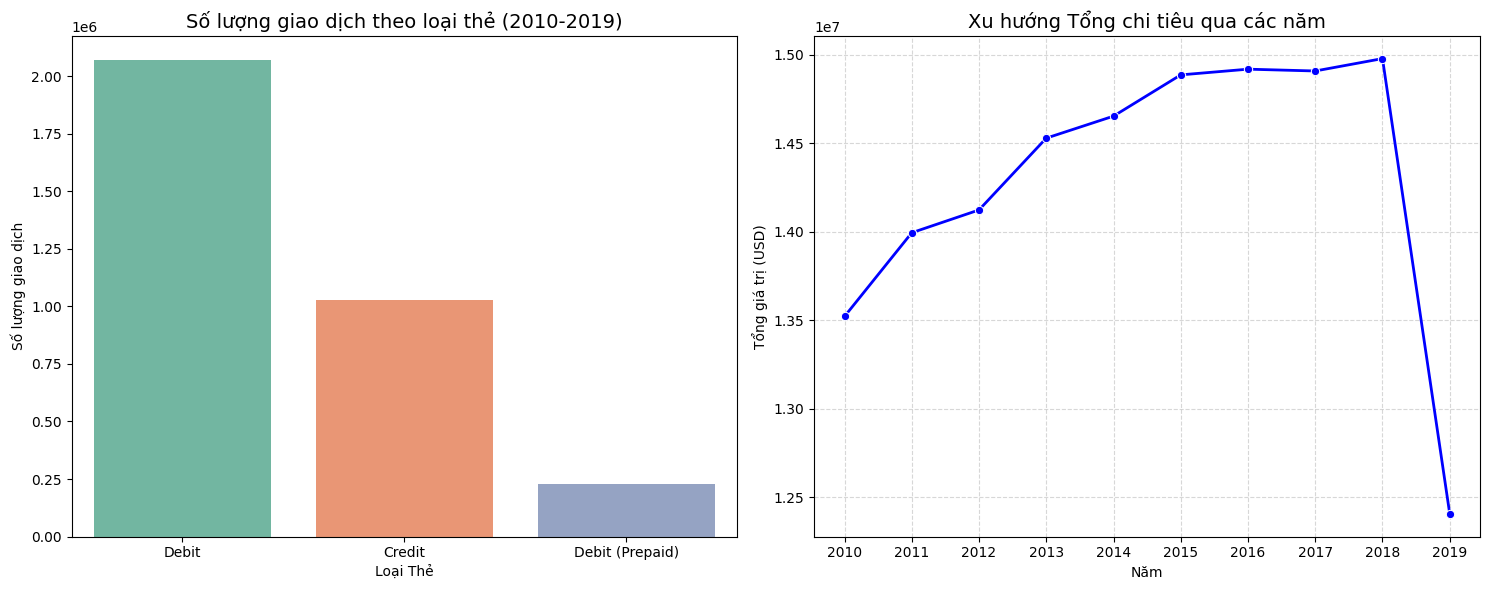

In [6]:
# ==========================================
# TRỰC QUAN HÓA BẰNG MATPLOTLIB & SEABORN
# ==========================================

# Cài đặt kích thước khung hình
plt.figure(figsize=(15, 6))

# Biểu đồ 1: Tỷ lệ Khách hàng dùng loại thẻ nào?
plt.subplot(1, 2, 1)
sns.countplot(data=df_2010_2019, x='card_type', palette='Set2')
plt.title('Số lượng giao dịch theo loại thẻ (2010-2019)', fontsize=14)
plt.xlabel('Loại Thẻ')
plt.ylabel('Số lượng giao dịch')

# Biểu đồ 2: Xu hướng tổng chi tiêu từ 2010 - 2019
plt.subplot(1, 2, 2)
# Tính tổng số tiền (amount) theo từng năm
trend_data = df_2010_2019.groupby('year')['amount'].sum().reset_index()
sns.lineplot(data=trend_data, x='year', y='amount', marker='o', color='b', linewidth=2)
plt.title('Xu hướng Tổng chi tiêu qua các năm', fontsize=14)
plt.xlabel('Năm')
plt.ylabel('Tổng giá trị (USD)')
plt.xticks(trend_data['year']) # Hiển thị đủ số năm trên trục x
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

--- THỐNG KÊ CHI TIÊU THEO NHÓM TUỔI ---
  age_group  total_spent  transaction_count
0   Dưới 30   4753127.71             107487
1   31 - 45  40817490.38             952637
2   46 - 60  52876963.09            1226080
3   Trên 60  44458019.51            1040275


C:\Users\admin\AppData\Local\Temp\ipykernel_19296\2412970304.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=age_summary, x='age_group', y='total_spent', palette='viridis')


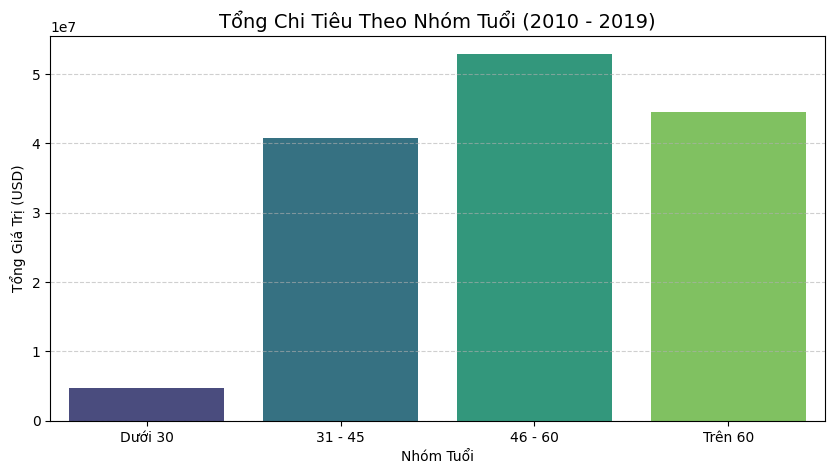

In [7]:
# ==========================================
# BƯỚC 5: PHÂN KHÚC KHÁCH HÀNG THEO ĐỘ TUỔI
# ==========================================

# Tạo một bản sao để tránh lỗi SettingWithCopyWarning của Pandas
df_analysis = df_2010_2019.copy()

# 1. Tạo các nhóm tuổi (Bins)
bins = [0, 30, 45, 60, 150]
labels_age = ['Dưới 30', '31 - 45', '46 - 60', 'Trên 60']
df_analysis['age_group'] = pd.cut(df_analysis['current_age'], bins=bins, labels=labels_age)

# 2. Tính tổng chi tiêu và số lượng giao dịch theo từng nhóm tuổi
age_summary = df_analysis.groupby('age_group').agg(
    total_spent=('amount', 'sum'),
    transaction_count=('id', 'count')
).reset_index()

print("--- THỐNG KÊ CHI TIÊU THEO NHÓM TUỔI ---")
print(age_summary)

# 3. Trực quan hóa
plt.figure(figsize=(10, 5))
sns.barplot(data=age_summary, x='age_group', y='total_spent', palette='viridis')
plt.title('Tổng Chi Tiêu Theo Nhóm Tuổi (2010 - 2019)', fontsize=14)
plt.xlabel('Nhóm Tuổi')
plt.ylabel('Tổng Giá Trị (USD)')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

--- TỶ LỆ GIAN LẬN TỔNG THỂ ---
Giao dịch an toàn: 99.85%
Giao dịch bị gian lận: 0.15%


C:\Users\admin\AppData\Local\Temp\ipykernel_19296\13109084.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=fraud_data, x='card_type', palette='Reds')
C:\Users\admin\AppData\Local\Temp\ipykernel_19296\13109084.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=fraud_data, x='use_chip', palette='Oranges')


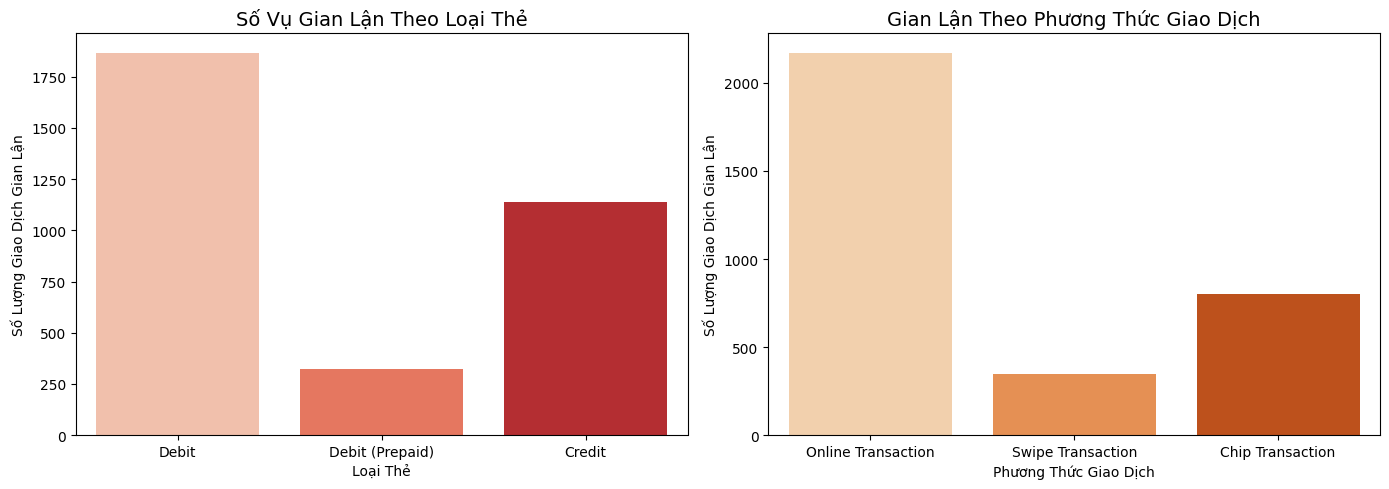

In [8]:
# ==========================================
# BƯỚC 6: PHÂN TÍCH GIAO DỊCH GIAN LẬN 
# ==========================================

# 1. Bỏ qua các giao dịch không có nhãn
df_fraud_valid = df_analysis.dropna(subset=['label']).copy()

# 2. Xử lý triệt để: Đưa tất cả về dạng chữ thường để chuẩn hóa (tránh 'No', 'no', 'NO')
df_fraud_valid['label'] = df_fraud_valid['label'].astype(str).str.strip().str.lower()

# Ánh xạ chữ thành số (no -> 0; yes -> 1)
# Phòng hờ trường hợp có cả số 0, 1 dạng chuỗi
label_mapping = {
    'no': 0, 'yes': 1, 
    '0': 0, '1': 1, 
    '0.0': 0, '1.0': 1
}
df_fraud_valid['label'] = df_fraud_valid['label'].map(label_mapping)

# 3. Tính toán tỷ lệ phần trăm
fraud_counts = df_fraud_valid['label'].value_counts(normalize=True) * 100

# Đổi tên index sang văn bản cho dễ đọc trên màn hình
fraud_display_mapping = {0: 'Giao dịch an toàn', 1: 'Giao dịch bị gian lận'}
fraud_counts.index = fraud_counts.index.map(fraud_display_mapping)

print("--- TỶ LỆ GIAN LẬN TỔNG THỂ ---")
for label_name, pct in fraud_counts.items():
    print(f"{label_name}: {pct:.2f}%")

# 4. Phân tích Gian lận để vẽ biểu đồ
# Lọc chính xác các giao dịch gian lận (label == 1)
fraud_data = df_fraud_valid[df_fraud_valid['label'] == 1]

if not fraud_data.empty:
    plt.figure(figsize=(14, 5))

    # Biểu đồ 1: Số lượng giao dịch gian lận theo loại thẻ
    plt.subplot(1, 2, 1)
    sns.countplot(data=fraud_data, x='card_type', palette='Reds')
    plt.title('Số Vụ Gian Lận Theo Loại Thẻ', fontsize=14)
    plt.xlabel('Loại Thẻ')
    plt.ylabel('Số Lượng Giao Dịch Gian Lận')

    # Biểu đồ 2: Gian lận Online (không dùng chip) vs Offline (dùng chip)
    plt.subplot(1, 2, 2)
    sns.countplot(data=fraud_data, x='use_chip', palette='Oranges')
    plt.title('Gian Lận Theo Phương Thức Giao Dịch', fontsize=14)
    plt.xlabel('Phương Thức Giao Dịch')
    plt.ylabel('Số Lượng Giao Dịch Gian Lận')

    plt.tight_layout()
    plt.show()
else:
    print("\nKhông tìm thấy dữ liệu giao dịch gian lận. Hãy kiểm tra lại dữ liệu nguồn.")

In [9]:
# ==========================================
# BƯỚC 7: XÂY DỰNG PHÂN KHÚC KHÁCH HÀNG (BẢN VÁ LỖI TRÙNG LẶP)
# ==========================================
import datetime as dt

# 1. Lấy ngày giao dịch gần nhất làm mốc hiện tại
current_date = df_analysis['date'].max() + dt.timedelta(days=1)

# 2. Tính R (Recency), F (Frequency), M (Monetary)
rfm = df_analysis.groupby('client_id').agg({
    'date': lambda x: (current_date - x.max()).days,  # R: Số ngày từ giao dịch cuối
    'id': 'count',                                    # F: Tổng số lần giao dịch
    'amount': 'sum'                                   # M: Tổng tiền chi tiêu
}).reset_index()
rfm.columns = ['client_id', 'Recency', 'Frequency', 'Monetary']

# 3. Chấm điểm 1-4 cho từng tiêu chí
# Bổ sung .rank(method='first') cho tất cả để ép xếp hạng duy nhất, tránh lỗi Bin edges
rfm['R_Score'] = pd.qcut(rfm['Recency'].rank(method='first'), q=4, labels=[4, 3, 2, 1])
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=4, labels=[1, 2, 3, 4])
rfm['M_Score'] = pd.qcut(rfm['Monetary'].rank(method='first'), q=4, labels=[1, 2, 3, 4])

# 4. Gộp điểm và gắn nhãn phân khúc
rfm['RFM_Segment'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)

def segment_customer(df):
    if df['RFM_Segment'] == '444':
        return 'Khách VIP (Champions)'
    elif df['F_Score'] == 4 and df['M_Score'] >= 3:
        return 'Khách Trung thành (Loyal)'
    elif df['R_Score'] == 1:
        return 'Khách Rời bỏ (Lost/At Risk)'
    else:
        return 'Khách Phổ thông (Regular)'

rfm['Customer_Segment'] = rfm.apply(segment_customer, axis=1)

print("--- THỐNG KÊ PHÂN KHÚC KHÁCH HÀNG ---")
print(rfm['Customer_Segment'].value_counts())

--- THỐNG KÊ PHÂN KHÚC KHÁCH HÀNG ---
Customer_Segment
Khách Phổ thông (Regular)      667
Khách Rời bỏ (Lost/At Risk)    285
Khách Trung thành (Loyal)      203
Khách VIP (Champions)           64
Name: count, dtype: int64


C:\Users\admin\AppData\Local\Temp\ipykernel_19296\2504289364.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_summary, x='Customer_Segment', y='Customer_Count', palette='viridis')
C:\Users\admin\AppData\Local\Temp\ipykernel_19296\2504289364.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_summary, x='Customer_Segment', y='Total_Revenue', palette='magma')


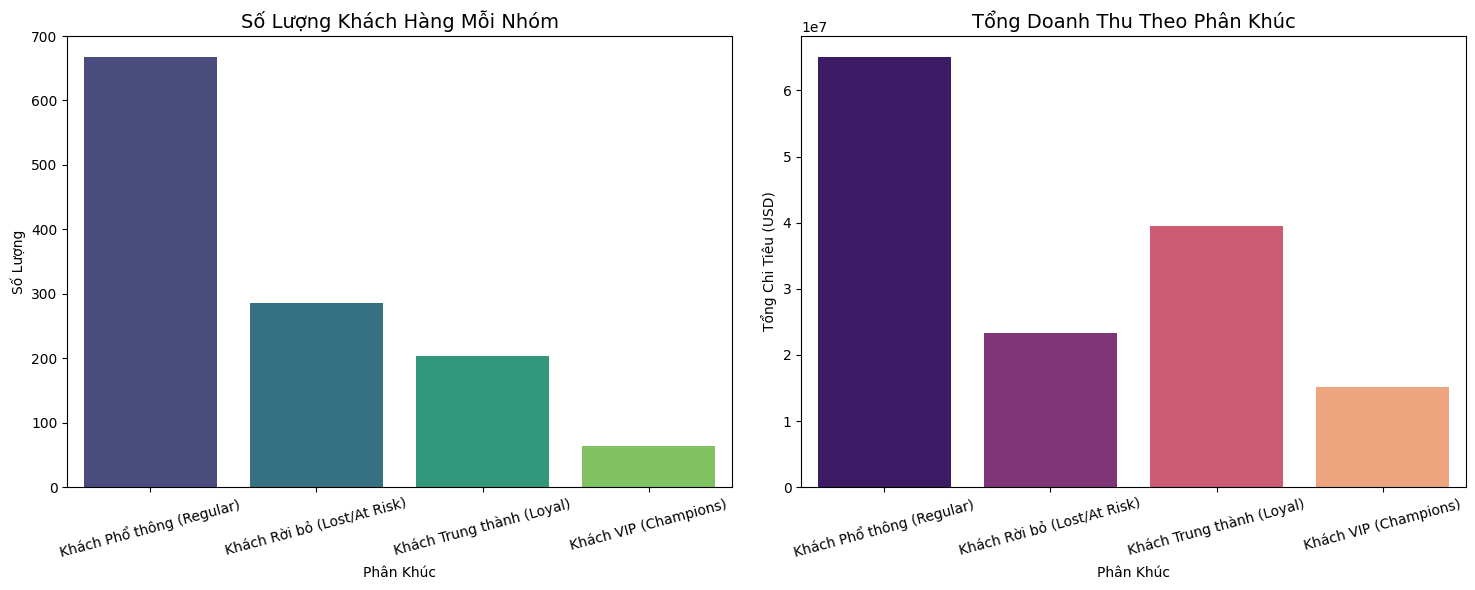

In [10]:
# ==========================================
# BƯỚC 8: TRỰC QUAN HÓA PHÂN KHÚC & CHI TIÊU
# ==========================================

# 1. Chuẩn bị dữ liệu vẽ biểu đồ
segment_summary = rfm.groupby('Customer_Segment').agg(
    Customer_Count=('client_id', 'count'),
    Total_Revenue=('Monetary', 'sum')
).reset_index()

plt.figure(figsize=(15, 6))

# Biểu đồ 1: Số lượng khách hàng theo phân khúc
plt.subplot(1, 2, 1)
sns.barplot(data=segment_summary, x='Customer_Segment', y='Customer_Count', palette='viridis')
plt.title('Số Lượng Khách Hàng Mỗi Nhóm', fontsize=14)
plt.xlabel('Phân Khúc')
plt.ylabel('Số Lượng')
plt.xticks(rotation=15)

# Biểu đồ 2: Tổng doanh thu mang lại theo phân khúc
plt.subplot(1, 2, 2)
sns.barplot(data=segment_summary, x='Customer_Segment', y='Total_Revenue', palette='magma')
plt.title('Tổng Doanh Thu Theo Phân Khúc', fontsize=14)
plt.xlabel('Phân Khúc')
plt.ylabel('Tổng Chi Tiêu (USD)')
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [11]:
# ==========================================
# BƯỚC 9: PHÂN TÍCH ĐỀ XUẤT CHIẾN LƯỢC (CROSS-SELL CREDIT CARD)
# ==========================================

# 1. Tìm những khách hàng giao dịch bằng thẻ Debit
debit_users = df_analysis[df_analysis['card_type'].isin(['Debit', 'Debit (Prepaid)'])]

# 2. Tính tổng chi tiêu Debit của họ
debit_spending = debit_users.groupby('client_id').agg(
    Total_Debit_Spend=('amount', 'sum')
).reset_index()

# 3. Kết hợp với phân khúc RFM để lọc ra "Khách VIP" hoặc "Khách Trung thành" đang dùng Debit
potential_cross_sell = pd.merge(debit_spending, rfm[['client_id', 'Customer_Segment']], on='client_id', how='left')

# Lọc nhóm tiềm năng nhất (Chi tiêu > 50,000$ bằng thẻ Debit và thuộc nhóm VIP/Trung thành)
high_value_targets = potential_cross_sell[
    (potential_cross_sell['Total_Debit_Spend'] > 50000) & 
    (potential_cross_sell['Customer_Segment'].isin(['Khách VIP (Champions)', 'Khách Trung thành (Loyal)']))
]

print("--- CHIẾN LƯỢC BÁN CHÉO (CROSS-SELL) ---")
print(f"Có {len(high_value_targets)} khách hàng chi tiêu rất lớn qua thẻ Debit.")
print("=> ĐỀ XUẤT: Gọi điện trực tiếp cho nhóm này để chào mời mở thẻ Credit Card với hạn mức cao và ưu đãi hoàn tiền (Cashback).")

# Hiển thị 5 khách hàng tiềm năng nhất để đội sale chăm sóc
print("\nTop 5 Khách hàng mục tiêu chiến dịch:")
print(high_value_targets.sort_values(by='Total_Debit_Spend', ascending=False).head(5))

--- CHIẾN LƯỢC BÁN CHÉO (CROSS-SELL) ---
Có 245 khách hàng chi tiêu rất lớn qua thẻ Debit.
=> ĐỀ XUẤT: Gọi điện trực tiếp cho nhóm này để chào mời mở thẻ Credit Card với hạn mức cao và ưu đãi hoàn tiền (Cashback).

Top 5 Khách hàng mục tiêu chiến dịch:
     client_id  Total_Debit_Spend           Customer_Segment
467        840          443694.61      Khách VIP (Champions)
278        490          416466.21      Khách VIP (Champions)
276        488          407452.87      Khách VIP (Champions)
646       1168          379888.91  Khách Trung thành (Loyal)
31          52          375529.42      Khách VIP (Champions)


--- ĐẶC ĐIỂM TRUNG BÌNH CỦA TỪNG PHÂN KHÚC ---
                             Recency  Frequency   Monetary  Số lượng KH
Customer_Segment                                                       
Khách Phổ thông (Regular)       1.40    2304.73   97470.02          667
Khách Rời bỏ (Lost/At Risk)    62.72    1865.06   81940.90          285
Khách Trung thành (Loyal)       4.50    4635.24  194225.60          203
Khách VIP (Champions)           1.00    4948.84  236127.21           64
--------------------------------------------------


C:\Users\admin\AppData\Local\Temp\ipykernel_19296\3988373046.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=rfm, x='Customer_Segment', y='Recency', palette='Set2', ax=axes[0])
C:\Users\admin\AppData\Local\Temp\ipykernel_19296\3988373046.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=rfm, x='Customer_Segment', y='Frequency', palette='Set2', ax=axes[1])
C:\Users\admin\AppData\Local\Temp\ipykernel_19296\3988373046.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=rfm, x='Customer_Segment', y='Monetary', palette='Se

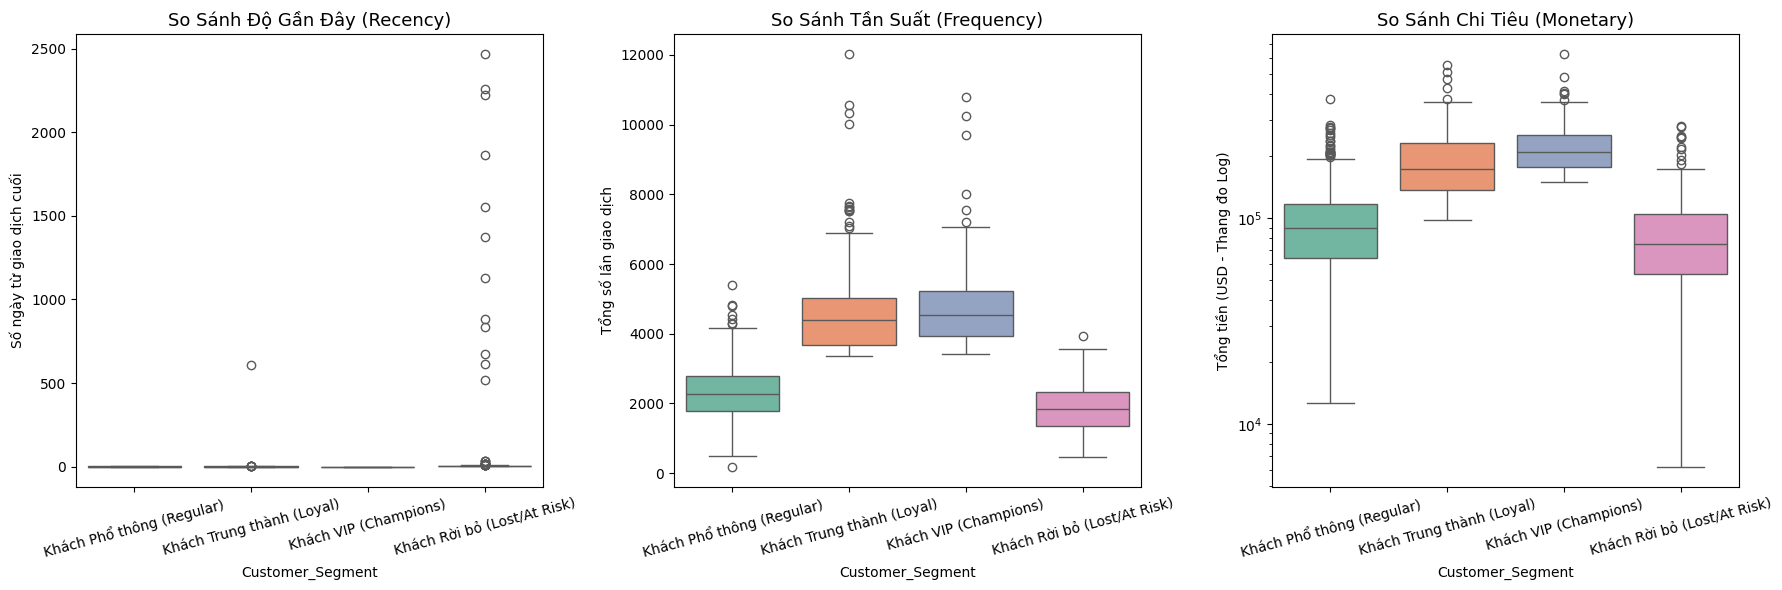

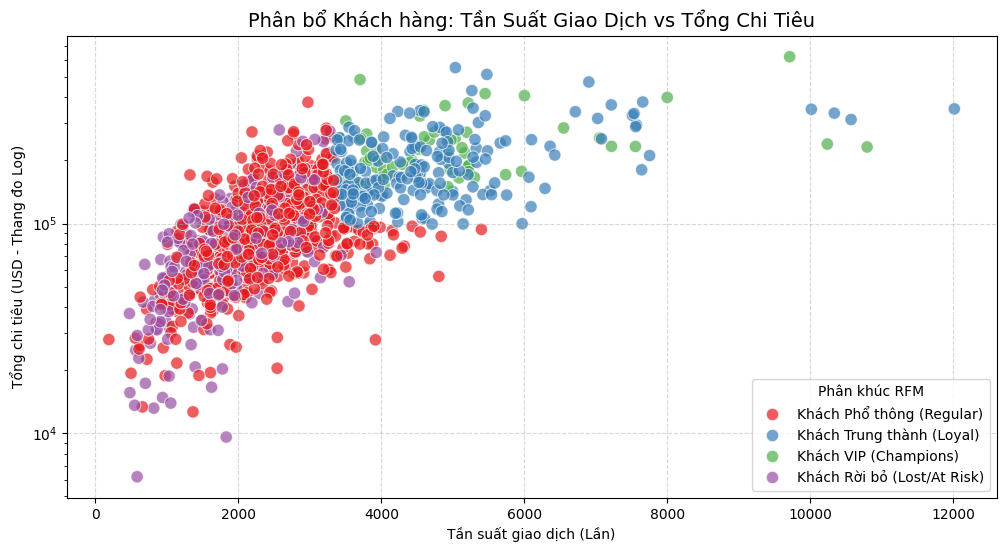

In [12]:
# ==========================================
# BƯỚC 8B: BIỂU ĐỒ SO SÁNH CHUYÊN SÂU CÁC PHÂN KHÚC RFM
# ==========================================

# 1. Bảng phân tích giá trị trung bình của từng nhóm
rfm_mean = rfm.groupby('Customer_Segment').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'client_id': 'count'
}).rename(columns={'client_id': 'Số lượng KH'}).round(2)

print("--- ĐẶC ĐIỂM TRUNG BÌNH CỦA TỪNG PHÂN KHÚC ---")
print(rfm_mean)
print("-" * 50)

# 2. Vẽ cụm biểu đồ Boxplot để so sánh phân bố R, F, M
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Biểu đồ Recency (Thời gian vắng mặt)
sns.boxplot(data=rfm, x='Customer_Segment', y='Recency', palette='Set2', ax=axes[0])
axes[0].set_title('So Sánh Độ Gần Đây (Recency)', fontsize=13)
axes[0].set_ylabel('Số ngày từ giao dịch cuối')
axes[0].tick_params(axis='x', rotation=15)

# Biểu đồ Frequency (Tần suất mua hàng)
sns.boxplot(data=rfm, x='Customer_Segment', y='Frequency', palette='Set2', ax=axes[1])
axes[1].set_title('So Sánh Tần Suất (Frequency)', fontsize=13)
axes[1].set_ylabel('Tổng số lần giao dịch')
axes[1].tick_params(axis='x', rotation=15)

# Biểu đồ Monetary (Tổng chi tiêu)
sns.boxplot(data=rfm, x='Customer_Segment', y='Monetary', palette='Set2', ax=axes[2])
axes[2].set_title('So Sánh Chi Tiêu (Monetary)', fontsize=13)
axes[2].set_ylabel('Tổng tiền (USD - Thang đo Log)')
axes[2].tick_params(axis='x', rotation=15)
axes[2].set_yscale('log') # Dùng thang đo log vì khoảng cách tiền tệ rất lớn

plt.tight_layout()
plt.show()

# 3. Vẽ biểu đồ phân tán (Scatter Plot) so sánh Tần suất và Chi tiêu
plt.figure(figsize=(12, 6))
sns.scatterplot(data=rfm, x='Frequency', y='Monetary', hue='Customer_Segment', palette='Set1', s=80, alpha=0.7)
plt.title('Phân bổ Khách hàng: Tần Suất Giao Dịch vs Tổng Chi Tiêu', fontsize=14)
plt.xlabel('Tần suất giao dịch (Lần)')
plt.ylabel('Tổng chi tiêu (USD - Thang đo Log)')
plt.yscale('log')
plt.legend(title='Phân khúc RFM')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

--- TỶ LỆ GIAN LẬN TỔNG THỂ ---
Giao dịch an toàn: 99.85%
Giao dịch bị gian lận: 0.15%



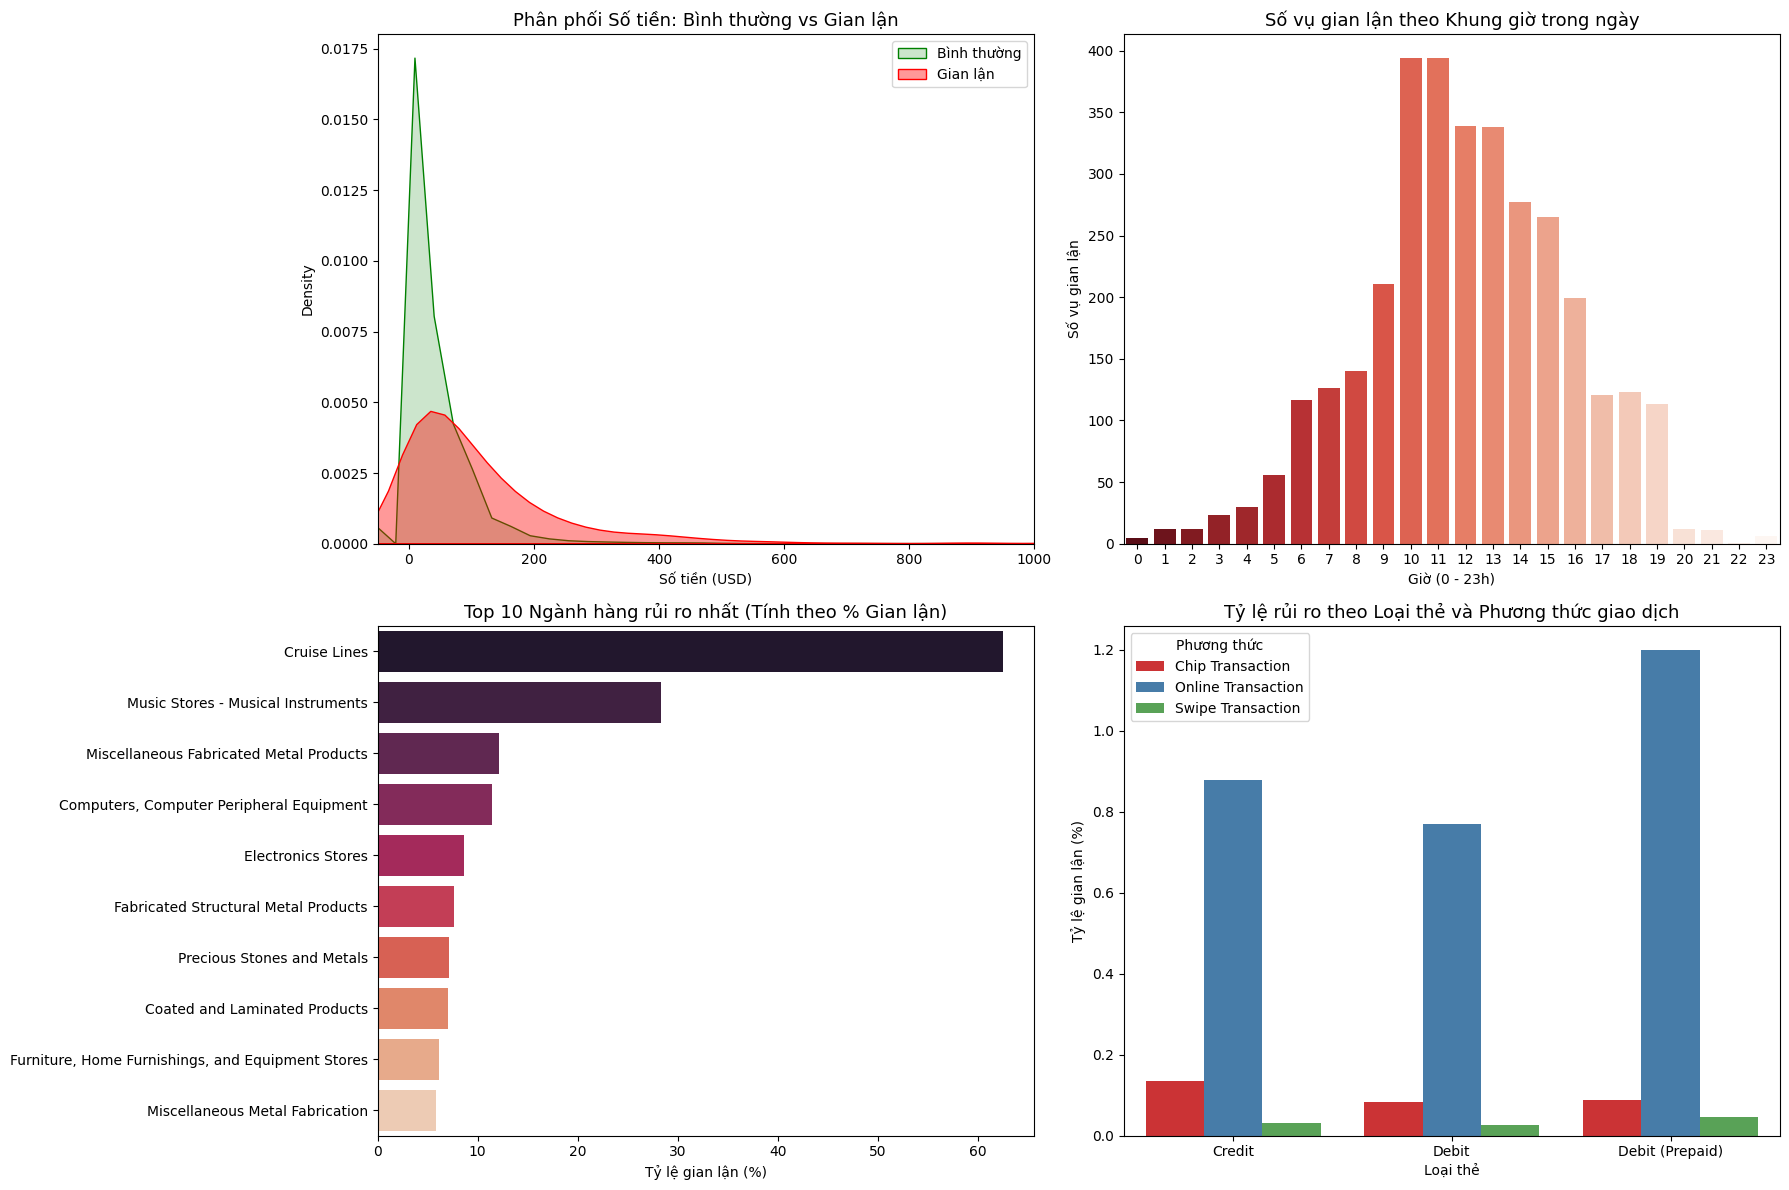

In [13]:
# ==========================================
# BƯỚC 6 (NÂNG CẤP): PHÂN TÍCH GIAN LẬN ĐA CHIỀU
# ==========================================
import warnings
warnings.filterwarnings('ignore') # Ẩn các cảnh báo deprecation của Seaborn

# 1. Tiền xử lý nhãn (Label)
df_fraud_valid = df_analysis.dropna(subset=['label']).copy()
df_fraud_valid['label'] = df_fraud_valid['label'].astype(str).str.strip().str.lower()

label_mapping = {'no': 0, 'yes': 1, '0': 0, '1': 1, '0.0': 0, '1.0': 1}
df_fraud_valid['label'] = df_fraud_valid['label'].map(label_mapping)

# Trích xuất thêm đặc trưng thời gian (Giờ & Ngày trong tuần)
df_fraud_valid['hour'] = df_fraud_valid['date'].dt.hour
df_fraud_valid['day_of_week'] = df_fraud_valid['date'].dt.day_name()

# Tách tập dữ liệu
fraud_data = df_fraud_valid[df_fraud_valid['label'] == 1]
normal_data = df_fraud_valid[df_fraud_valid['label'] == 0]

print("--- TỶ LỆ GIAN LẬN TỔNG THỂ ---")
fraud_counts = df_fraud_valid['label'].value_counts(normalize=True) * 100
print(f"Giao dịch an toàn: {fraud_counts[0]:.2f}%")
print(f"Giao dịch bị gian lận: {fraud_counts[1]:.2f}%\n")

if not fraud_data.empty:
    # Thiết lập khung biểu đồ 2x2
    fig, axes = plt.subplots(2, 2, figsize=(18, 12))
    
    # --- Biểu đồ 1: Phân phối số tiền giao dịch (KDE Plot) ---
    # Mục đích: Xem xét gian lận thường nằm ở những khoản tiền lớn hay nhỏ
    sns.kdeplot(data=normal_data, x='amount', label='Bình thường', fill=True, color='green', alpha=0.2, ax=axes[0, 0])
    sns.kdeplot(data=fraud_data, x='amount', label='Gian lận', fill=True, color='red', alpha=0.4, ax=axes[0, 0])
    axes[0, 0].set_title('Phân phối Số tiền: Bình thường vs Gian lận', fontsize=13)
    axes[0, 0].set_xlim(-50, 1000) # Cắt bớt đuôi nhiễu (outliers) để dễ nhìn
    axes[0, 0].set_xlabel('Số tiền (USD)')
    axes[0, 0].legend()

    # --- Biểu đồ 2: Tần suất gian lận theo Khung giờ ---
    # Mục đích: Nhận diện thời điểm hacker thường hoạt động
    sns.countplot(data=fraud_data, x='hour', palette='Reds_r', ax=axes[0, 1], hue='hour', legend=False)
    axes[0, 1].set_title('Số vụ gian lận theo Khung giờ trong ngày', fontsize=13)
    axes[0, 1].set_xlabel('Giờ (0 - 23h)')
    axes[0, 1].set_ylabel('Số vụ gian lận')

    # --- Biểu đồ 3: Top 10 Ngành hàng (MCC) có TỶ LỆ gian lận cao nhất ---
    # Lưu ý: Dùng tỷ lệ % thay vì đếm số lượng tuyệt đối để đánh giá rủi ro chính xác hơn
    fraud_rate_mcc = df_fraud_valid.groupby('merchant_category')['label'].mean().sort_values(ascending=False).head(10) * 100
    sns.barplot(x=fraud_rate_mcc.values, y=fraud_rate_mcc.index, palette='rocket', ax=axes[1, 0], hue=fraud_rate_mcc.index, legend=False)
    axes[1, 0].set_title('Top 10 Ngành hàng rủi ro nhất (Tính theo % Gian lận)', fontsize=13)
    axes[1, 0].set_xlabel('Tỷ lệ gian lận (%)')
    axes[1, 0].set_ylabel('')

    # --- Biểu đồ 4: Tỷ lệ gian lận theo Loại thẻ & Phương thức (Chip/Swipe/Online) ---
    fraud_rate_type = df_fraud_valid.groupby(['card_type', 'use_chip'])['label'].mean().reset_index()
    fraud_rate_type['label'] = fraud_rate_type['label'] * 100 # Chuyển sang phần trăm
    
    sns.barplot(data=fraud_rate_type, x='card_type', y='label', hue='use_chip', palette='Set1', ax=axes[1, 1])
    axes[1, 1].set_title('Tỷ lệ rủi ro theo Loại thẻ và Phương thức giao dịch', fontsize=13)
    axes[1, 1].set_xlabel('Loại thẻ')
    axes[1, 1].set_ylabel('Tỷ lệ gian lận (%)')
    axes[1, 1].legend(title='Phương thức')

    plt.tight_layout()
    plt.show()
else:
    print("Không tìm thấy dữ liệu giao dịch gian lận.")

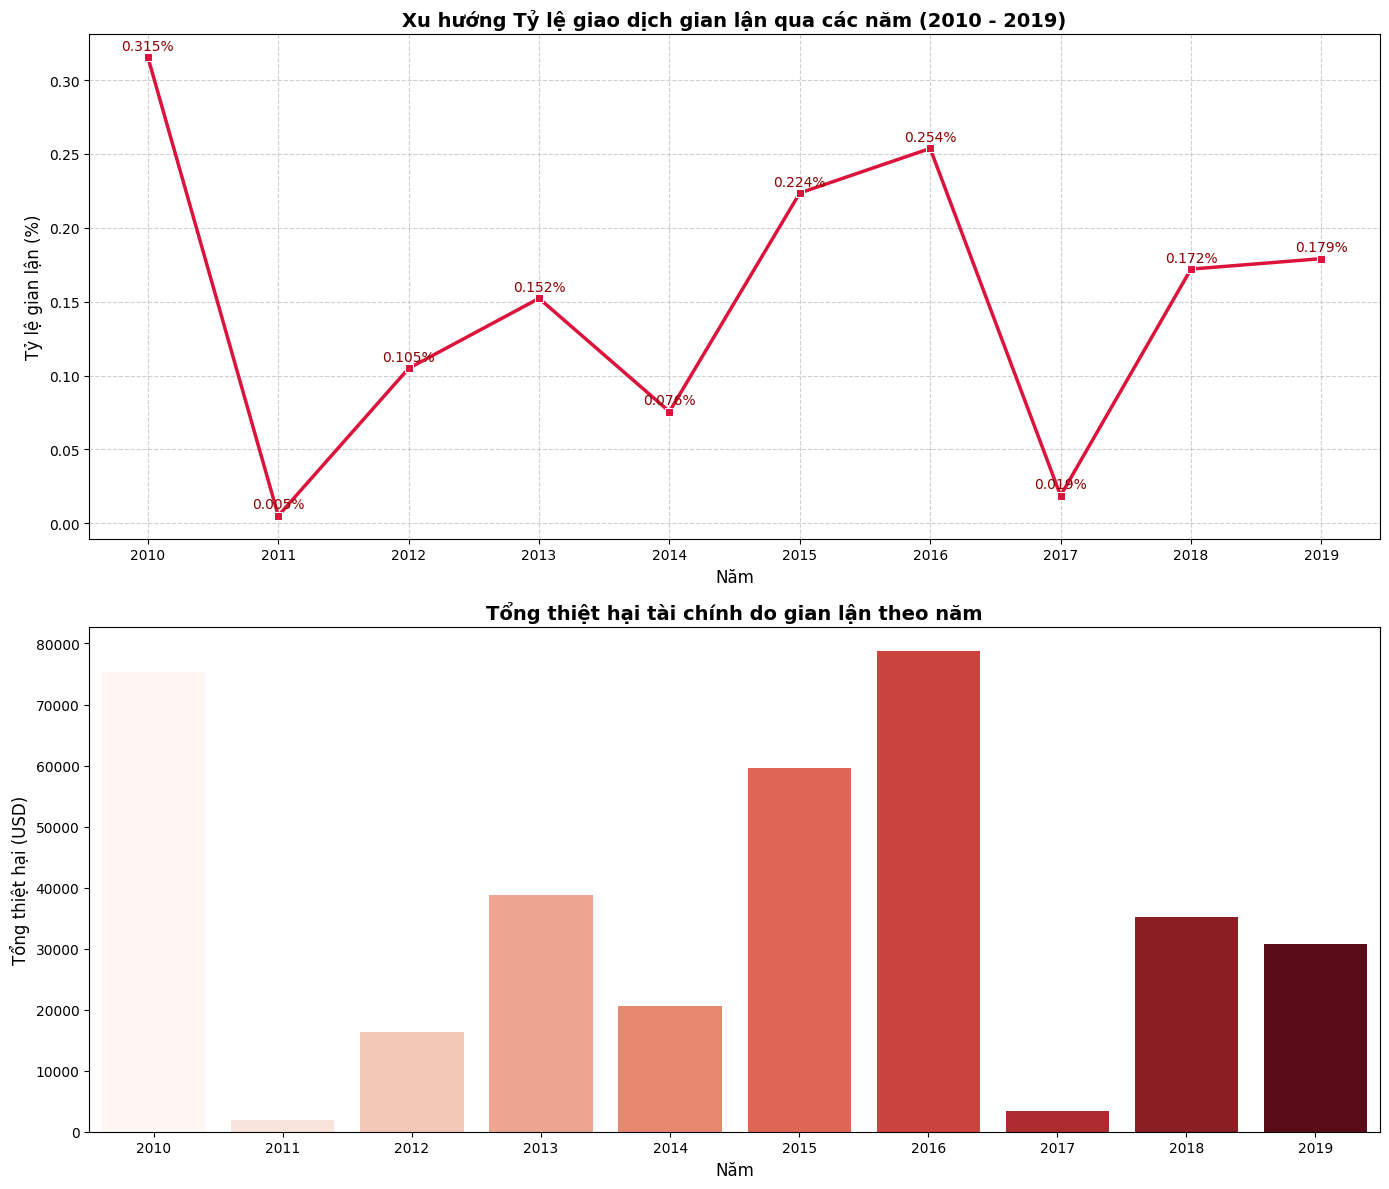

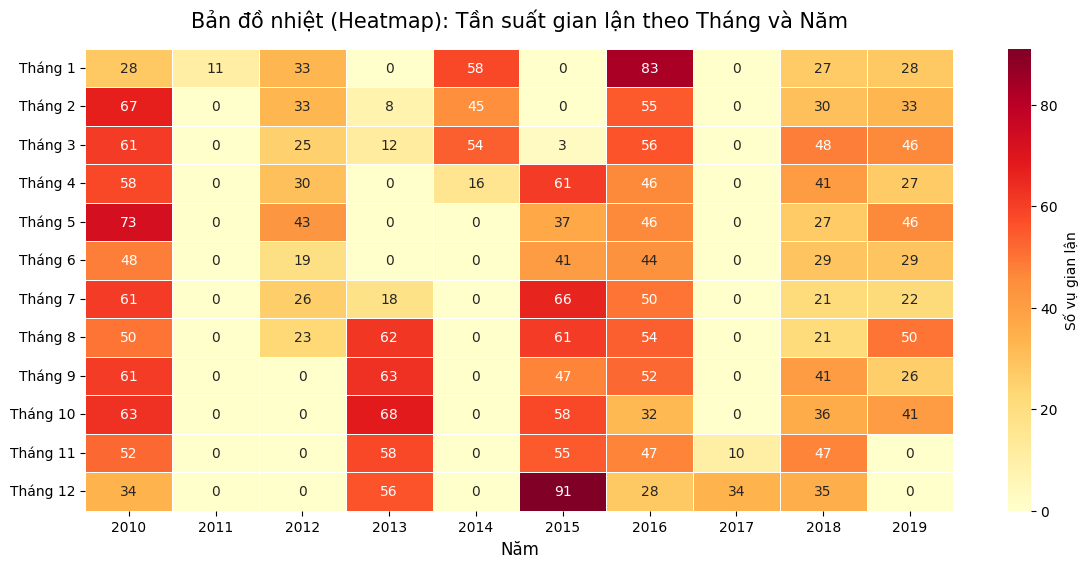

In [14]:
# ==========================================
# BƯỚC 6.2: PHÂN TÍCH XU HƯỚNG GIAN LẬN THEO THỜI GIAN (2010 - 2019)
# ==========================================

# 1. Tính toán Tỷ lệ gian lận và Tổng thiệt hại theo từng năm
# Lưu ý: Tính tỷ lệ % sẽ khách quan hơn là chỉ đếm số lượng, vì tổng giao dịch mỗi năm có thể khác nhau.
yearly_fraud_stats = df_fraud_valid.groupby('year').agg(
    total_transactions=('id', 'count'),
    fraud_transactions=('label', 'sum'), # Nhãn 1 là gian lận, tính tổng sẽ ra số vụ
    total_fraud_amount=('amount', lambda x: x[df_fraud_valid.loc[x.index, 'label'] == 1].sum())
).reset_index()

# Tính tỷ lệ % gian lận trên tổng giao dịch của năm đó
yearly_fraud_stats['fraud_rate_pct'] = (yearly_fraud_stats['fraud_transactions'] / yearly_fraud_stats['total_transactions']) * 100

# 2. Trực quan hóa Xu hướng theo năm
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# --- Biểu đồ 1: Xu hướng Tỷ lệ gian lận theo năm (Line Plot) ---
sns.lineplot(data=yearly_fraud_stats, x='year', y='fraud_rate_pct', marker='s', color='crimson', linewidth=2.5, ax=axes[0])
axes[0].set_title('Xu hướng Tỷ lệ giao dịch gian lận qua các năm (2010 - 2019)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Năm', fontsize=12)
axes[0].set_ylabel('Tỷ lệ gian lận (%)', fontsize=12)
axes[0].set_xticks(yearly_fraud_stats['year'])
axes[0].grid(True, linestyle='--', alpha=0.6)

# Ghi chú trực tiếp con số tỷ lệ lên biểu đồ để dễ đọc
for i, row in yearly_fraud_stats.iterrows():
    axes[0].text(row['year'], row['fraud_rate_pct'] + 0.005, f"{row['fraud_rate_pct']:.3f}%", ha='center', color='darkred')

# --- Biểu đồ 2: Tổng thiệt hại tài chính do gian lận (Bar Plot) ---
sns.barplot(data=yearly_fraud_stats, x='year', y='total_fraud_amount', palette='Reds', ax=axes[1], hue='year', legend=False)
axes[1].set_title('Tổng thiệt hại tài chính do gian lận theo năm', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Năm', fontsize=12)
axes[1].set_ylabel('Tổng thiệt hại (USD)', fontsize=12)

plt.tight_layout()
plt.show()

# ==========================================
# BƯỚC 6.3: PHÂN TÍCH TÍNH MÙA VỤ BẰNG BẢN ĐỒ NHIỆT (HEATMAP)
# ==========================================
plt.figure(figsize=(14, 6))

# Tạo bảng pivot đếm số vụ gian lận theo Tháng (index) và Năm (columns)
fraud_pivot = df_fraud_valid[df_fraud_valid['label'] == 1].pivot_table(
    index='month', 
    columns='year', 
    values='id', 
    aggfunc='count', 
    fill_value=0
)

# Đổi số tháng thành tên tháng cho biểu đồ chuyên nghiệp hơn
fraud_pivot.index = ['Tháng ' + str(i) for i in fraud_pivot.index]

# Vẽ Heatmap
sns.heatmap(fraud_pivot, cmap='YlOrRd', annot=True, fmt='g', linewidths=0.5, cbar_kws={'label': 'Số vụ gian lận'})
plt.title('Bản đồ nhiệt (Heatmap): Tần suất gian lận theo Tháng và Năm', fontsize=15, pad=15)
plt.xlabel('Năm', fontsize=12)
plt.ylabel('', fontsize=12)
plt.yticks(rotation=0)

plt.show()

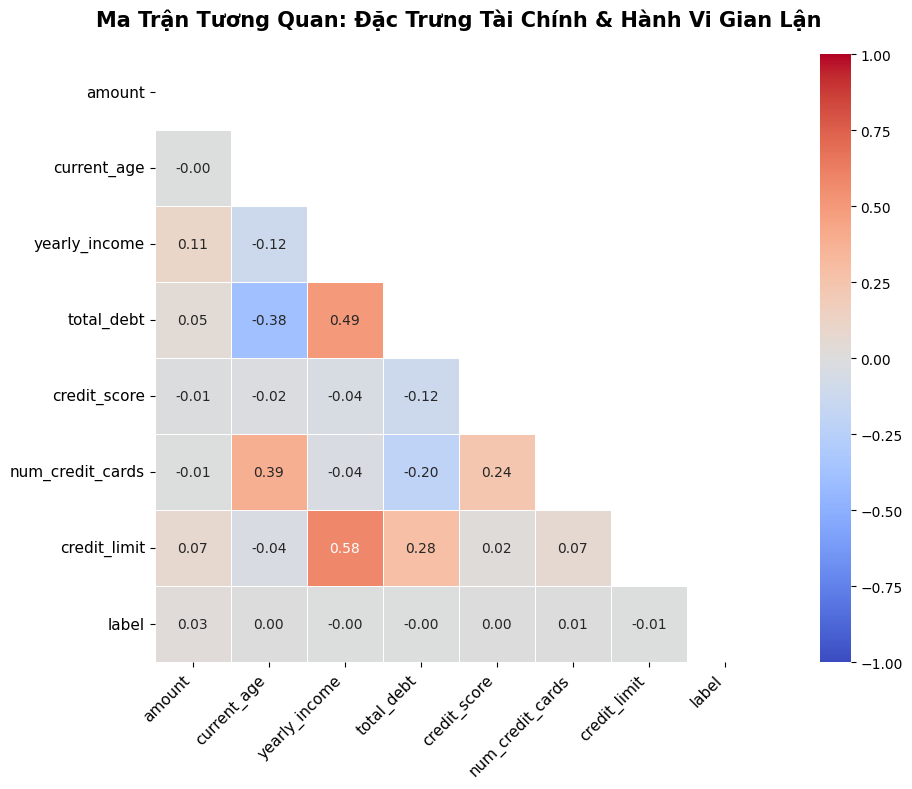

In [15]:
# ==========================================
# BƯỚC 7: PHÂN TÍCH ĐA BIẾN - MA TRẬN TƯƠNG QUAN (CORRELATION MATRIX)
# ==========================================
import numpy as np

# 1. Chọn các biến số (numerical features) quan trọng cần phân tích
# Bao gồm các thông tin tài chính, nhân khẩu học và nhãn gian lận
cols_to_corr = [
    'amount', 'current_age', 'yearly_income', 
    'total_debt', 'credit_score', 'num_credit_cards', 
    'credit_limit', 'label'
]

# Lọc dữ liệu, loại bỏ các giá trị rỗng (nếu có) để tính toán chính xác
df_corr = df_fraud_valid[cols_to_corr].dropna()

# 2. Tính toán ma trận tương quan (Hệ số Pearson)
corr_matrix = df_corr.corr()

# 3. Trực quan hóa bằng Heatmap (Bản đồ nhiệt)
plt.figure(figsize=(12, 8))

# Tạo mask để ẩn nửa trên của ma trận (vì ma trận tương quan có tính đối xứng)
# Giúp biểu đồ bớt rối mắt và chuyên nghiệp hơn
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Vẽ biểu đồ
sns.heatmap(
    corr_matrix, 
    mask=mask,
    annot=True,          # Hiển thị hệ số tương quan trên từng ô
    fmt=".2f",           # Làm tròn 2 chữ số thập phân
    cmap='coolwarm',     # Thang màu: Đỏ (tương quan dương), Xanh (tương quan âm)
    vmin=-1, vmax=1,     # Giới hạn thang đo từ -1 đến 1
    linewidths=0.5,      # Đường viền giữa các ô
    square=True
)

plt.title('Ma Trận Tương Quan: Đặc Trưng Tài Chính & Hành Vi Gian Lận', fontsize=15, pad=20, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.yticks(rotation=0, fontsize=11)

plt.tight_layout()
plt.show()